# Moving Average Crossover Trading Strategy

This notebook retrieves historical stock prices from the Yahoo Finance API, generates buy and sell signals from a short-term/long-term simple moving average (SMA) crossover, backtests the strategy, and compares it with buy-and-hold.

**Rules**
- **Buy** when the short-term SMA crosses above the long-term SMA.
- **Sell** (move to cash) when the short-term SMA crosses below the long-term SMA.

Each trade is charged a transaction cost, and the results are tested across several window lengths.

Run the cells in order from top to bottom (Kernel > Restart & Run All).

## Setup
Install the required packages.

In [1]:
%pip install -q yfinance pandas numpy matplotlib

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

TRADING_DAYS = 252

## Parameters
Change these to test a different ticker, period, or window length. `END` is fixed so the results can be reproduced; Yahoo Finance treats it as exclusive, so the last trading day included is the day before.

In [3]:
TICKER = "SPY"
START = "2015-01-01"
END = "2026-11-14"   # exclusive: data runs through 2026-11-13
SHORT_WINDOW = 20    # short-term moving average (days)
LONG_WINDOW = 50     # long-term moving average (days)
COST_BPS = 5.0       # transaction cost per trade (entry or exit), in basis points

## 1. Retrieve historical price data
Daily closing prices, adjusted for splits and dividends, are downloaded through the `yfinance` API.

In [4]:
def fetch_prices(ticker: str, start: str, end: str | None = None) -> pd.Series:
    """Download daily adjusted closing prices from the Yahoo Finance API."""
    import yfinance as yf

    data = yf.download(ticker, start=start, end=end, auto_adjust=True, progress=False)
    if data.empty:
        raise ValueError(f"No data returned for {ticker}.")
    close = data["Close"]
    if isinstance(close, pd.DataFrame):  # newer yfinance returns MultiIndex columns
        close = close.iloc[:, 0]
    return close.dropna().rename("price")

In [5]:
price = fetch_prices(TICKER, START, END)
print(f"{len(price)} trading days from {price.index[0].date()} to {price.index[-1].date()}")
price.tail()

2985 trading days from 2015-01-02 to 2026-11-13


Date
2026-11-09    752.690002
2026-11-10    749.919983
2026-11-11    759.809998
2026-11-12    757.119995
2026-11-13    754.369995
Name: price, dtype: float64

## 2. Calculate moving averages and signals
- `position` is 1 when the short SMA is above the long SMA (hold the stock) and 0 otherwise (hold cash).
- `signal` is +1 on the day of a buy crossover and -1 on the day of a sell crossover.

The first `LONG_WINDOW` days are dropped because the long SMA does not exist yet.

In [6]:
def build_signals(price: pd.Series, short: int, long: int) -> pd.DataFrame:
    """
    Compute moving averages and crossover signals.

    position =  1 when short MA > long MA (hold the stock), else 0 (hold cash)
    signal   = +1 on a buy crossover, -1 on a sell crossover, 0 otherwise
    """
    if short >= long:
        raise ValueError("Short window must be smaller than long window.")

    df = pd.DataFrame({"price": price})
    df["sma_short"] = df["price"].rolling(short).mean()
    df["sma_long"] = df["price"].rolling(long).mean()
    df = df.dropna()  # drop warm-up period before the long MA exists

    df["position"] = (df["sma_short"] > df["sma_long"]).astype(int)
    df["signal"] = df["position"].diff().fillna(0)
    return df

In [7]:
signals = build_signals(price, SHORT_WINDOW, LONG_WINDOW)
signals[signals["signal"] != 0].head(10)

,price,sma_short,sma_long,position,signal
Date,,,,,
2015-04-20,173.681274,172.217171,172.223676,0,-1.0
2015-04-24,175.171066,172.763005,172.600775,1,1.0
2015-06-25,174.534439,174.565718,174.581967,0,-1.0
2015-08-03,174.476196,174.345633,174.284484,1,1.0
2015-08-19,173.253662,174.112766,174.142519,0,-1.0
2015-10-22,171.596207,165.786909,165.252061,1,1.0
2015-12-22,171.137375,172.606184,172.639241,0,-1.0
2016-03-09,167.672546,163.219225,162.657701,1,1.0
2016-05-26,176.956635,174.397467,174.423081,0,-1.0


## 3. Backtest
The position is lagged by one day: a crossover observed at today's close is traded the next day. This avoids look-ahead bias (using information that was not yet available when the trade was made).

Each entry and exit is charged `COST_BPS`. Cash earns 0%. Buy-and-hold is measured over exactly the same dates and is charged no costs.

In [8]:
def backtest(df: pd.DataFrame, cost_bps: float = 0.0) -> pd.DataFrame:
    """
    Backtest the long-only crossover strategy against buy-and-hold.

    The position is lagged one day: a crossover observed at today's close is
    traded on, and earns returns from, the next day. This avoids look-ahead bias.
    """
    df = df.copy()
    df["ret"] = df["price"].pct_change().fillna(0)

    held = df["position"].shift(1).fillna(0)           # position actually held
    trades = held.diff().abs().fillna(held.abs())      # 1 whenever we enter/exit
    costs = trades * cost_bps / 10_000

    df["strategy_ret"] = held * df["ret"] - costs
    df["strategy_equity"] = (1 + df["strategy_ret"]).cumprod()
    df["buyhold_equity"] = (1 + df["ret"]).cumprod()
    return df

In [9]:
bt = backtest(signals, COST_BPS)
bt[["price", "position", "strategy_equity", "buyhold_equity"]].tail()

,price,position,strategy_equity,buyhold_equity
Date,,,,
2026-11-09,752.690002,0,2.429231,4.379593
2026-11-10,749.919983,0,2.429231,4.363475
2026-11-11,759.809998,0,2.429231,4.421021
2026-11-12,757.119995,0,2.429231,4.405369
2026-11-13,754.369995,0,2.429231,4.389368


## 4. Performance: strategy vs. buy-and-hold
- **Total return**: growth over the full period.
- **Annualized volatility**: standard deviation of daily returns, scaled by the square root of 252.
- **Sharpe ratio**: annualized return divided by annualized volatility (risk-free rate assumed to be 0).
- **Maximum drawdown**: largest peak-to-trough decline in portfolio value.

In [10]:
def performance(returns: pd.Series) -> dict:
    equity = (1 + returns).cumprod()
    years = len(returns) / TRADING_DAYS
    total_return = equity.iloc[-1] - 1
    ann_return = (1 + total_return) ** (1 / years) - 1
    ann_vol = returns.std() * np.sqrt(TRADING_DAYS)
    sharpe = ann_return / ann_vol if ann_vol > 0 else np.nan  # risk-free rate = 0
    drawdown = equity / equity.cummax() - 1
    return {
        "Total return": total_return,
        "Annualized return": ann_return,
        "Annualized volatility": ann_vol,
        "Sharpe ratio (rf=0)": sharpe,
        "Maximum drawdown": drawdown.min(),
    }


def summary_table(bt: pd.DataFrame) -> pd.DataFrame:
    table = pd.DataFrame(
        {
            "MA Crossover": performance(bt["strategy_ret"]),
            "Buy & Hold": performance(bt["ret"]),
        }
    )
    table.loc["Buy signals"] = [(bt["signal"] == 1).sum(), np.nan]
    table.loc["Sell signals"] = [(bt["signal"] == -1).sum(), np.nan]
    table.loc["Time in market"] = [bt["position"].mean(), 1.0]
    return table


def format_values(table: pd.DataFrame) -> pd.DataFrame:
    pct_rows = {
        "Total return", "Annualized return", "Annualized volatility",
        "Maximum drawdown", "Time in market",
    }
    out = table.astype(object).copy()
    for row in table.index:
        for col in table.columns:
            v = table.loc[row, col]
            if pd.isna(v):
                out.loc[row, col] = "-"
            elif row in pct_rows:
                out.loc[row, col] = f"{v:.2%}"
            elif row.startswith("Sharpe"):
                out.loc[row, col] = f"{v:.2f}"
            else:
                out.loc[row, col] = f"{int(v)}"
    return out


def format_table(table: pd.DataFrame) -> str:
    return format_values(table).to_string()

In [11]:
print(f"{TICKER} | {SHORT_WINDOW}/{LONG_WINDOW} SMA crossover | "
      f"{bt.index[0].date()} to {bt.index[-1].date()} | cost {COST_BPS} bps/trade\n")
print(format_table(summary_table(bt)))

SPY | 20/50 SMA crossover | 2015-03-16 to 2026-11-13 | cost 5.0 bps/trade

                      MA Crossover Buy & Hold
Total return               142.92%    338.94%
Annualized return            7.92%     13.54%
Annualized volatility       11.35%     17.59%
Sharpe ratio (rf=0)           0.70       0.77
Maximum drawdown           -29.24%    -33.72%
Buy signals                     26          -
Sell signals                    27          -
Time in market              72.45%    100.00%


## 5. Sensitivity to window lengths
A result that only holds for one pair of windows is likely to be overfit. The same backtest is repeated for several short/long pairs. All pairs are measured from the same start date (once the longest moving average exists), so the rows are comparable with each other and with buy-and-hold.

In [12]:
WINDOW_PAIRS = [(10, 30), (20, 50), (50, 100), (50, 200)]


def sensitivity(price: pd.Series, pairs: list[tuple[int, int]], cost_bps: float) -> pd.DataFrame:
    """Backtest each (short, long) pair over a common period and compare with buy-and-hold."""
    common_start = price.index[max(long for _, long in pairs) - 1]
    rows = {}
    for short, long in pairs:
        df = build_signals(price, short, long).loc[common_start:]
        result = backtest(df, cost_bps)
        stats = performance(result["strategy_ret"])
        stats["Trades"] = result["position"].shift(1).fillna(0).diff().abs().fillna(0).sum()
        rows[f"{short}/{long} SMA"] = stats
    bh = backtest(build_signals(price, *pairs[0]).loc[common_start:], 0.0)
    rows["Buy & Hold"] = {**performance(bh["ret"]), "Trades": 0}
    table = pd.DataFrame(rows).T

    out = table.astype(object).copy()
    for col in table.columns:
        if col.startswith("Sharpe"):
            out[col] = table[col].map(lambda v: f"{v:.2f}")
        elif col == "Trades":
            out[col] = table[col].map(lambda v: f"{int(v)}")
        else:
            out[col] = table[col].map(lambda v: f"{v:.2%}")
    print(f"{TICKER} | {common_start.date()} to {price.index[-1].date()} | cost {cost_bps} bps/trade\n")
    print(out.to_string())
    return table


sens = sensitivity(price, WINDOW_PAIRS, COST_BPS)

SPY | 2015-10-16 to 2026-11-13 | cost 5.0 bps/trade

           Total return Annualized return Annualized volatility Sharpe ratio (rf=0) Maximum drawdown Trades
10/30 SMA       127.80%             7.73%                11.00%                0.70          -18.08%     84
20/50 SMA       143.69%             8.39%                11.53%                0.73          -29.24%     48
50/100 SMA       92.21%             6.09%                13.87%                0.44          -34.29%     21
50/200 SMA      165.43%             9.23%                14.93%                0.62          -33.72%     11
Buy & Hold      343.92%            14.43%                17.67%                0.82          -33.72%      0


## 6. Charts

In [13]:
def plot_results(bt: pd.DataFrame, ticker: str, short: int, long: int, path: str) -> None:
    fig, axes = plt.subplots(
        3, 1, figsize=(12, 11), sharex=True, gridspec_kw={"height_ratios": [3, 2, 1.5]}
    )

    ax = axes[0]
    ax.plot(bt.index, bt["price"], color="0.35", lw=1, label="Price")
    ax.plot(bt.index, bt["sma_short"], color="tab:blue", lw=1.2, label=f"{short}-day SMA")
    ax.plot(bt.index, bt["sma_long"], color="tab:orange", lw=1.2, label=f"{long}-day SMA")
    buys, sells = bt[bt["signal"] == 1], bt[bt["signal"] == -1]
    ax.scatter(buys.index, buys["price"], marker="^", color="green", s=60, zorder=3, label="Buy")
    ax.scatter(sells.index, sells["price"], marker="v", color="red", s=60, zorder=3, label="Sell")
    ax.set_title(f"{ticker}: Price, Moving Averages, and Crossover Signals")
    ax.set_ylabel("Price ($)")
    ax.legend(loc="upper left")

    ax = axes[1]
    ax.plot(bt.index, bt["strategy_equity"], color="tab:blue", label="MA Crossover")
    ax.plot(bt.index, bt["buyhold_equity"], color="0.35", label="Buy & Hold")
    ax.set_title("Growth of $1")
    ax.set_ylabel("Portfolio value ($)")
    ax.legend(loc="upper left")

    ax = axes[2]
    for col, color, label in [
        ("strategy_equity", "tab:blue", "MA Crossover"),
        ("buyhold_equity", "0.35", "Buy & Hold"),
    ]:
        dd = bt[col] / bt[col].cummax() - 1
        ax.plot(bt.index, dd * 100, color=color, lw=1, label=label)
    ax.set_title("Drawdown")
    ax.set_ylabel("Drawdown (%)")
    ax.legend(loc="lower left")

    for ax in axes:
        ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()
    print(f"Chart saved to {path}")

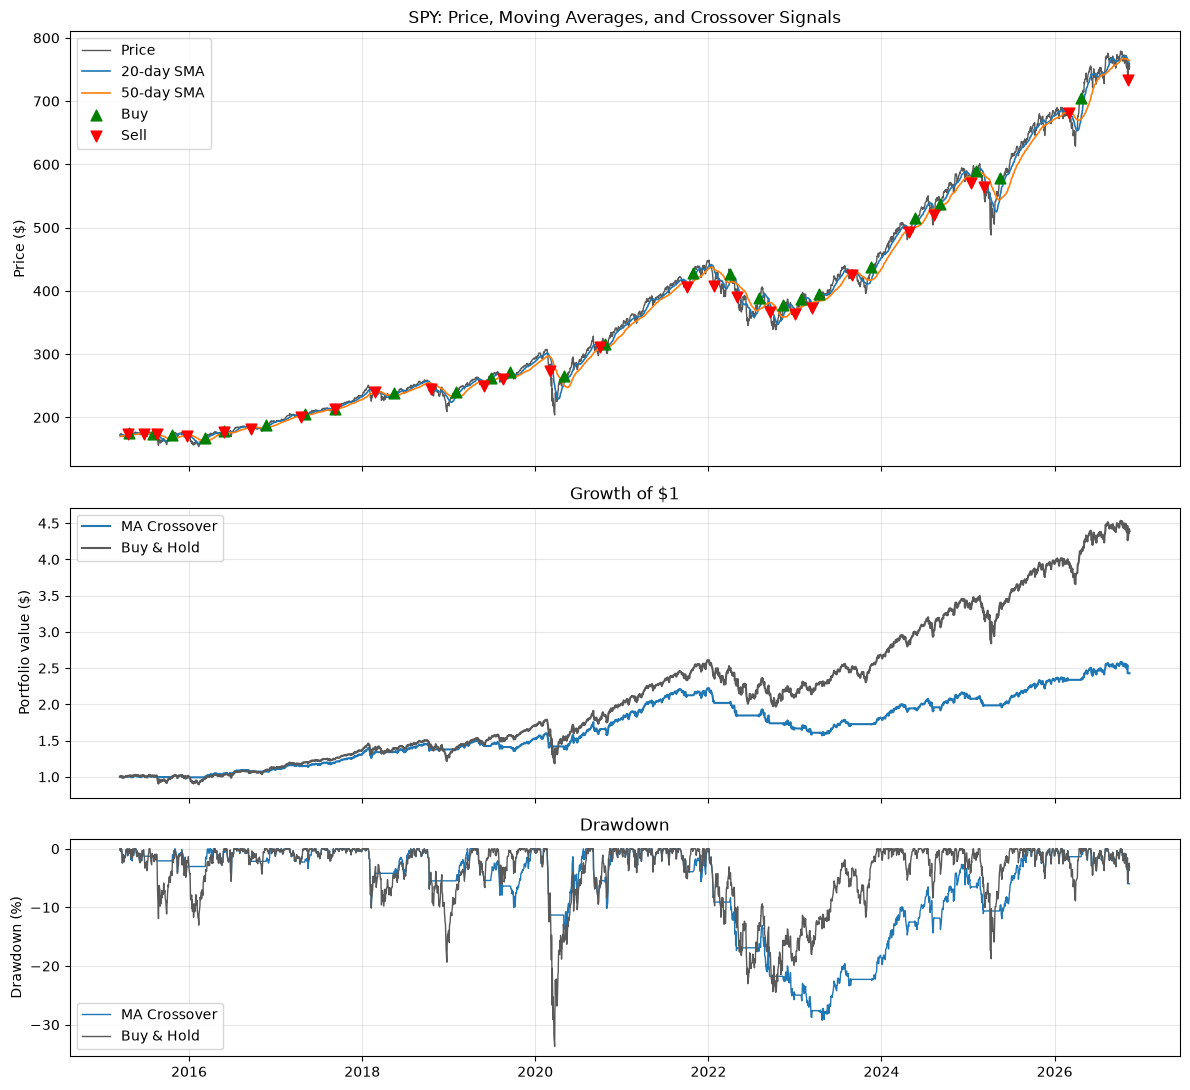

Chart saved to SPY_ma_crossover.png


In [14]:
plot_results(bt, TICKER, SHORT_WINDOW, LONG_WINDOW, f"{TICKER}_ma_crossover.png")

## 7. Save results
The CSV is excluded from the repository (see `.gitignore`) because the notebook regenerates it. The last cell prints the summary table in Markdown for the README.

In [15]:
bt.to_csv(f"{TICKER}_backtest.csv")
print(f"Daily results saved to {TICKER}_backtest.csv")

Daily results saved to SPY_backtest.csv


In [16]:
vals = format_values(summary_table(bt))
print("| Metric | " + " | ".join(vals.columns) + " |")
print("|---|" + "---:|" * len(vals.columns))
for metric, row in vals.iterrows():
    print(f"| {metric} | " + " | ".join(row) + " |")


| Metric | MA Crossover | Buy & Hold |
|---|---:|---:|
| Total return | 142.92% | 338.94% |
| Annualized return | 7.92% | 13.54% |
| Annualized volatility | 11.35% | 17.59% |
| Sharpe ratio (rf=0) | 0.70 | 0.77 |
| Maximum drawdown | -29.24% | -33.72% |
| Buy signals | 26 | - |
| Sell signals | 27 | - |
| Time in market | 72.45% | 100.00% |


## 8. Conclusion

Over March 2015 to November 2026, the 20/50-day crossover did not beat buy-and-hold on SPY. After transaction costs it returned 7.9% a year against 13.5% for buy-and-hold, and its Sharpe ratio was lower (0.70 against 0.77).

The strategy did reduce overall risk. Annualized volatility fell from 17.6% to 11.4%, and the maximum drawdown was 29.2% against 33.7%. The chart shows where most of the protection came from: the strategy moved to cash early in the 2020 crash and avoided most of buy-and-hold's 34% fall.

It struggled in markets without a clear trend. In 2022 and 2023 the price crossed the moving averages repeatedly, so the strategy sold after declines and bought back after rallies several times. Its drawdown in that period was deeper and lasted longer than buy-and-hold's, and that is where its own maximum drawdown came from. Together with the time spent in cash during a strongly rising market (about 28% of the period), these false signals cost more return than the crash protection saved.

The result does not depend on the choice of windows. None of the four pairs tested in Section 5 beat buy-and-hold on return or Sharpe ratio: annual returns ranged from 6.1% to 9.2% against 14.4%. Shorter windows reduced drawdowns the most; the 10/30 pair limited the maximum drawdown to 18.1%. The slowest pair, 50/200, had the same maximum drawdown as buy-and-hold, because it was still invested during the worst decline.

**Limitations**
- One asset and one period, with no prolonged bear market such as 2008. Trend-following strategies tend to compare better in long declines.
- Cash earns 0%. Including interest on cash would narrow the gap with buy-and-hold, especially in recent years.
- Costs are a flat 5 bps per trade; taxes and slippage beyond that are ignored.

**Next steps**
- Test other assets, such as sector ETFs and futures.
- Credit interest on cash at the Treasury bill rate.
- Use walk-forward testing: choose the windows on one period and evaluate them on the next.